# 07 - Deep tabular model: MLP with embeddings

A neural network on the structured features (PyTorch).

- Numeric columns are scaled and fed in directly.
- Each categorical column gets an **embedding**: a small trainable vector per level. This replaces one-hot encoding, which would create tens of thousands of columns for streets and wards.

Requires `pip install -r ../requirements-extra.txt`.

In [1]:
import copy
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, StandardScaler

SEED = 42
NUMERIC = ["area", "floor_count", "frontage_width", "house_depth", "road_width",
           "bedroom_count", "bathroom_count"]
CATEGORICAL = ["property_type_name", "province_name", "district_name", "ward_name",
               "street_name", "project_name", "house_direction", "balcony_direction"]

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Data

In [2]:
# run on colab only
from google.colab import drive
drive.mount("/content/drive")
import shutil

DRIVE_DIR = "/content/drive/MyDrive/Ps4AI"

# copy the data from Drive to the Colab disk (much faster to read)
shutil.copy(f"{DRIVE_DIR}/model_input.parquet", "/content/model_input.parquet")

# results (../reports/...) are saved to Ps4AI/reports on Drive
os.makedirs(f"{DRIVE_DIR}/notebooks", exist_ok=True)
os.chdir(f"{DRIVE_DIR}/notebooks")

Mounted at /content/drive


In [3]:
# df = pd.read_parquet("../data/processed/model_input.parquet",
#                      columns=NUMERIC + CATEGORICAL + ["price", "split"])

# run on colab so put the data file into colab folder
df = pd.read_parquet("/content/model_input.parquet",
                     columns=NUMERIC + CATEGORICAL + ["price", "split"])

train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
test = df[df["split"] == "test"]

## Preprocessing

Both transformers are fitted on the training set only.

- **Numeric:** `log1p` -> fill missing values with the median (plus a "was missing" flag) -> standardize. Neural networks train poorly when inputs have very different scales.
- **Categorical:** each level becomes an integer code. Levels seen fewer than 5 times share one code, and we add 1 so that code `0` means "never seen in training".

In [4]:
numeric = make_pipeline(
    FunctionTransformer(np.log1p),
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
)
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=5)

numeric.fit(train[NUMERIC])
encoder.fit(train[CATEGORICAL])


def to_tensors(part):
    num = torch.tensor(numeric.transform(part[NUMERIC]), dtype=torch.float32)
    cat = torch.tensor(encoder.transform(part[CATEGORICAL]) + 1, dtype=torch.long)
    target = torch.tensor(np.log1p(part["price"].to_numpy()), dtype=torch.float32)
    return num, cat, target


num_train, cat_train, y_train = to_tensors(train)
num_val, cat_val, y_val = to_tensors(val)
num_test, cat_test, y_test = to_tensors(test)

cardinalities = (cat_train.max(dim=0).values + 1).tolist()   # number of codes per column
pd.Series(cardinalities, index=CATEGORICAL, name="levels")

,levels
property_type_name,6
province_name,64
district_name,581
ward_name,3722
street_name,9844
project_name,3442
house_direction,14
balcony_direction,14


## Model

```
numeric features ─┐
embeddings ───────┴─ concat -> Linear -> ReLU -> Dropout -> Linear -> ReLU -> Dropout -> Linear -> log1p(price)
```

The embedding size grows slowly with the number of levels and is capped at 32 (a common rule of thumb from fastai).

In [5]:
class TabularMLP(nn.Module):
    def __init__(self, n_numeric, cardinalities, hidden=256, dropout=0.2):
        super().__init__()
        self.embeddings = nn.ModuleList(
            [nn.Embedding(n, min(32, round(1.6 * n ** 0.56))) for n in cardinalities]
        )
        n_inputs = n_numeric + sum(emb.embedding_dim for emb in self.embeddings)
        self.body = nn.Sequential(
            nn.Linear(n_inputs, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        )
        self.head = nn.Linear(hidden, 1)

    def forward(self, num, cat):
        embedded = [emb(cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat([num] + embedded, dim=1)
        return self.head(self.body(x)).squeeze(1)


model = TabularMLP(num_train.shape[1], cardinalities).to(device)
model.head.bias.data.fill_(y_train.mean())   # start from the average log price
model

TabularMLP(
  (embeddings): ModuleList(
    (0): Embedding(6, 4)
    (1): Embedding(64, 16)
    (2): Embedding(581, 32)
    (3): Embedding(3722, 32)
    (4): Embedding(9844, 32)
    (5): Embedding(3442, 32)
    (6-7): 2 x Embedding(14, 7)
  )
  (body): Sequential(
    (0): Linear(in_features=175, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (head): Linear(in_features=256, out_features=1, bias=True)
)

## Training

- **AdamW** optimizer, **Huber loss** (like MSE for small errors, like MAE for large ones, so wrongly entered prices do less harm).
- After each epoch we measure the MAE of the log price on the validation set.
- **Early stopping:** training stops after 3 epochs without improvement and the best weights are restored.

In [6]:
@torch.no_grad()
def predict(model, num, cat):
    model.eval()
    loader = DataLoader(TensorDataset(num, cat), batch_size=8192)
    return torch.cat([model(n.to(device), c.to(device)).cpu() for n, c in loader]).numpy()

In [7]:
EPOCHS = 30
PATIENCE = 3

train_loader = DataLoader(TensorDataset(num_train, cat_train, y_train), batch_size=1024, shuffle=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.HuberLoss()

history = []
best_mae, best_state, waited = float("inf"), None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for num, cat, target in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(num.to(device), cat.to(device)), target.to(device))
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    val_mae = np.abs(predict(model, num_val, cat_val) - y_val.numpy()).mean()
    history.append({"epoch": epoch, "train_loss": train_loss / len(train_loader), "val_mae": val_mae})
    print(f"epoch {epoch:2d}  train loss {history[-1]['train_loss']:.4f}  val MAE (log) {val_mae:.4f}")

    if val_mae < best_mae:
        best_mae, best_state, waited = val_mae, copy.deepcopy(model.state_dict()), 0
    else:
        waited += 1
        if waited == PATIENCE:
            break

model.load_state_dict(best_state)

epoch  1  train loss 0.0970  val MAE (log) 0.2503
epoch  2  train loss 0.0750  val MAE (log) 0.2413
epoch  3  train loss 0.0706  val MAE (log) 0.2362
epoch  4  train loss 0.0680  val MAE (log) 0.2313
epoch  5  train loss 0.0661  val MAE (log) 0.2375
epoch  6  train loss 0.0647  val MAE (log) 0.2317
epoch  7  train loss 0.0634  val MAE (log) 0.2301
epoch  8  train loss 0.0625  val MAE (log) 0.2303
epoch  9  train loss 0.0617  val MAE (log) 0.2286
epoch 10  train loss 0.0609  val MAE (log) 0.2246
epoch 11  train loss 0.0603  val MAE (log) 0.2266
epoch 12  train loss 0.0598  val MAE (log) 0.2287
epoch 13  train loss 0.0592  val MAE (log) 0.2248


<All keys matched successfully>

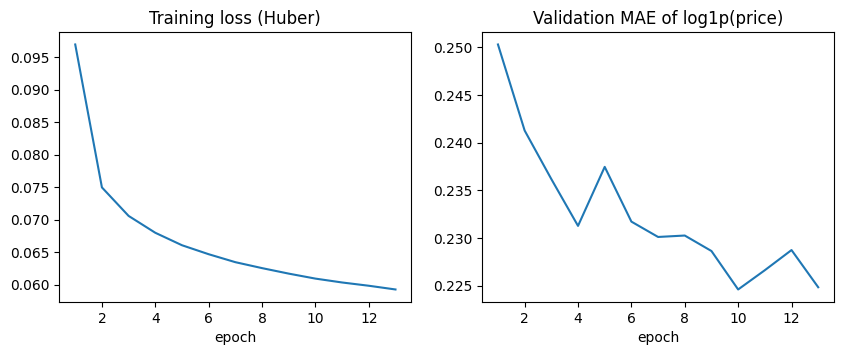

In [8]:
history = pd.DataFrame(history).set_index("epoch")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
history["train_loss"].plot(ax=axes[0], title="Training loss (Huber)")
history["val_mae"].plot(ax=axes[1], title="Validation MAE of log1p(price)")
plt.show()

## Results

In [9]:
def evaluate(y_true, y_pred):
    return {
        "MAE (bn VND)": mean_absolute_error(y_true, y_pred) / 1e9,
        "RMSE (bn VND)": root_mean_squared_error(y_true, y_pred) / 1e9,
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


pred = np.expm1(predict(model, num_test, cat_test))
table = pd.DataFrame({"MLP + embeddings": evaluate(test["price"], pred)}).T

os.makedirs("../reports/metrics", exist_ok=True)
table.to_csv("../reports/metrics/07_deep_tabular.csv")

table.style.format("{:,.3f}")

,MAE (bn VND),RMSE (bn VND),R2,MAPE (%)
MLP + embeddings,4.620,19.264,0.707,26.832


## Save predictions

Notebook 10 combines the models, so it needs each model's prediction of `log1p(price)` for every validation and test row.
The index is the row number in `model_input.parquet`, which lets notebook 10 line up the predictions of different notebooks.

In [10]:
predictions = pd.concat([
    pd.DataFrame({"split": "val", "MLP": predict(model, num_val, cat_val)}, index=val.index),
    pd.DataFrame({"split": "test", "MLP": predict(model, num_test, cat_test)}, index=test.index),
])

os.makedirs("../reports/predictions", exist_ok=True)
predictions.to_parquet("../reports/predictions/07_deep_tabular.parquet")
predictions.head()

,split,MLP
1677900,val,22.841642
1677901,val,22.278290
1677902,val,21.710030
1677903,val,23.430143
1677904,val,21.898005
